
# <h1 align="center"> **Laboratory Activity 1: Coin Detection**
<center>(Computer Vision)</center>

---


# <h3>**The Libraries**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# <h3>**Loading the Image**

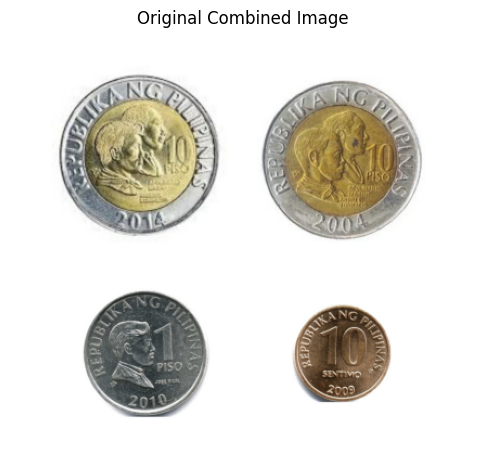

In [2]:
# Load the image (handles PNGs with or without a transparent channel)
image = cv2.imread('coins.png', cv2.IMREAD_UNCHANGED)

if image.ndim == 3 and image.shape[2] == 4:
    # Composite transparent pixels onto white so they don't turn into black "background"
    alpha = image[:, :, 3:4].astype(np.float32) / 255.0
    image = (image[:, :, :3] * alpha + 255 * (1 - alpha)).astype(np.uint8)

img_display = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(img_display)
plt.title('Original Combined Image')
plt.axis('off')
plt.show()

# <h3>**Pre-Processing**

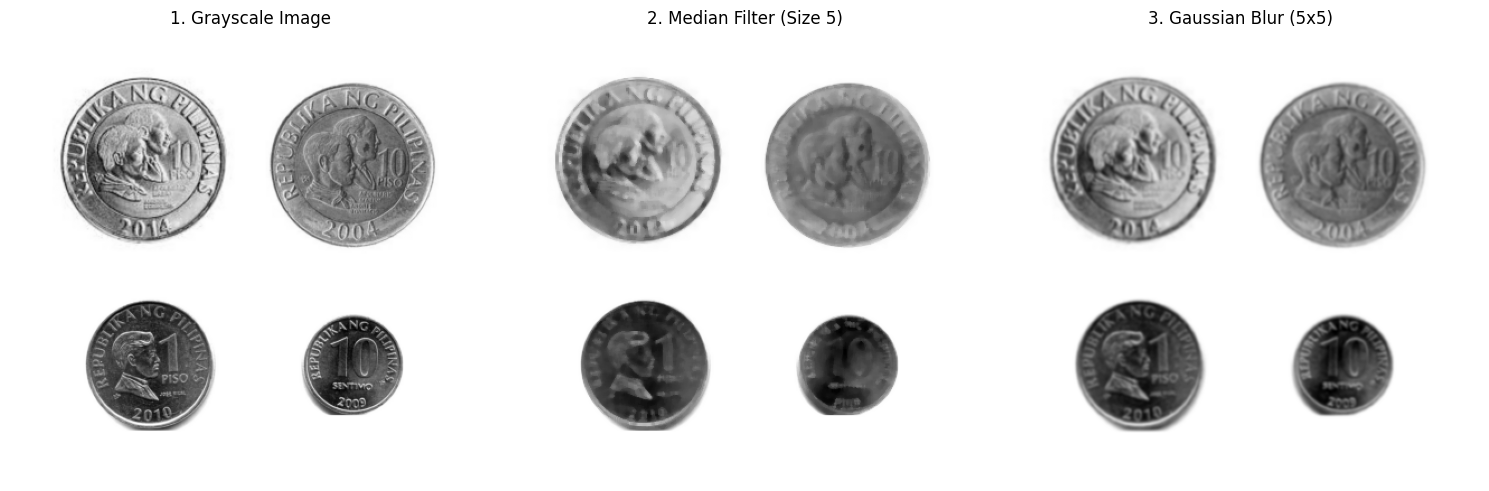

In [3]:
# 1. Convert to Grayscale
img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# 2. Apply Noise Reduction
# Option A: Median Filter
img_median = cv2.medianBlur(img_gray, 5)

# Option B: Gaussian Blur
img_gaussian = cv2.GaussianBlur(img_gray, (5, 5), 0)

# Visualization
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('1. Grayscale Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_median, cmap='gray')
plt.title('2. Median Filter (Size 5)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_gaussian, cmap='gray')
plt.title('3. Gaussian Blur (5x5)')
plt.axis('off')

plt.tight_layout()
plt.show()

# <h3>**Applying Convolution**

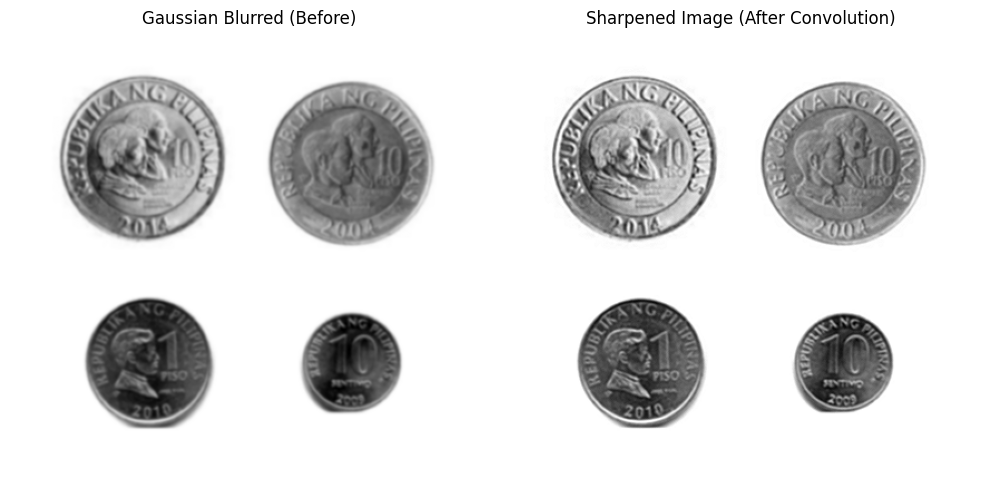

In [4]:

# Define the Sharpening Kernel matrix
sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])

# Apply the convolution operation using filter2D
img_sharpened = cv2.filter2D(img_gaussian, -1, sharpen_kernel)

# Visualization
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gaussian, cmap='gray')
plt.title('Gaussian Blurred (Before)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_sharpened, cmap='gray')
plt.title('Sharpened Image (After Convolution)')
plt.axis('off')

plt.tight_layout()
plt.show()


# <h3>**Locating the Coins (Silhouette Mask)**

In [5]:
# The coins sit on a plain white background, so the cleanest way to isolate them is to
# measure how far each pixel is from white (the largest drop in any colour channel).
# Using colour distance (not grayscale) keeps the bright silver rims from vanishing.
smooth_bgr = cv2.GaussianBlur(image, (5, 5), 0)
bg_distance = np.max(255 - smooth_bgr.astype(np.int16), axis=2).astype(np.uint8)

_, mask = cv2.threshold(bg_distance, 15, 255, cv2.THRESH_BINARY)

# Close gaps along the rim, then open to remove specks and shadows
k_mask = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k_mask, iterations=2)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  k_mask)

# Keep only external contours, filter by size + roundness, and fit an ellipse to each
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
min_area = 0.002 * image.shape[0] * image.shape[1]

coins = []   # one dict per detected coin
for c in contours:
    hull = cv2.convexHull(c)                     # coins are convex -> repairs any dents
    area, perim = cv2.contourArea(hull), cv2.arcLength(hull, True)
    if area < min_area or perim == 0:
        continue
    circularity = 4 * np.pi * area / perim ** 2  # 1.0 = perfect circle
    if circularity < 0.80:                       # lower this if your coins are tilted
        continue
    coins.append({
        "hull": hull,
        "ellipse": cv2.fitEllipse(hull),         # ((cx, cy), (d1, d2), angle)
        "area": area,
        "circularity": circularity,
    })

# Sort top-to-bottom, then left-to-right so numbering is stable
coins.sort(key=lambda d: (round(d["ellipse"][0][1] / 100), d["ellipse"][0][0]))

coin_mask = np.zeros_like(mask)
for coin in coins:
    cv2.drawContours(coin_mask, [coin["hull"]], -1, 255, cv2.FILLED)

print(f"Detected {len(coins)} coins")

Detected 4 coins


# <h3>**Performing Edge Detection**

In [6]:
# Pick Canny thresholds automatically from the brightness of the COIN pixels only
# (the white background would otherwise skew the median and push thresholds too high).
coin_median = np.median(img_sharpened[coin_mask > 0])
low_t  = int(max(0,   0.50 * coin_median))
high_t = int(min(255, 1.20 * coin_median))
print(f"Canny thresholds -> low: {low_t}, high: {high_t}")

edges = cv2.Canny(img_sharpened, low_t, high_t)

Canny thresholds -> low: 69, high: 165


# <h3>**Cleaning the Result**

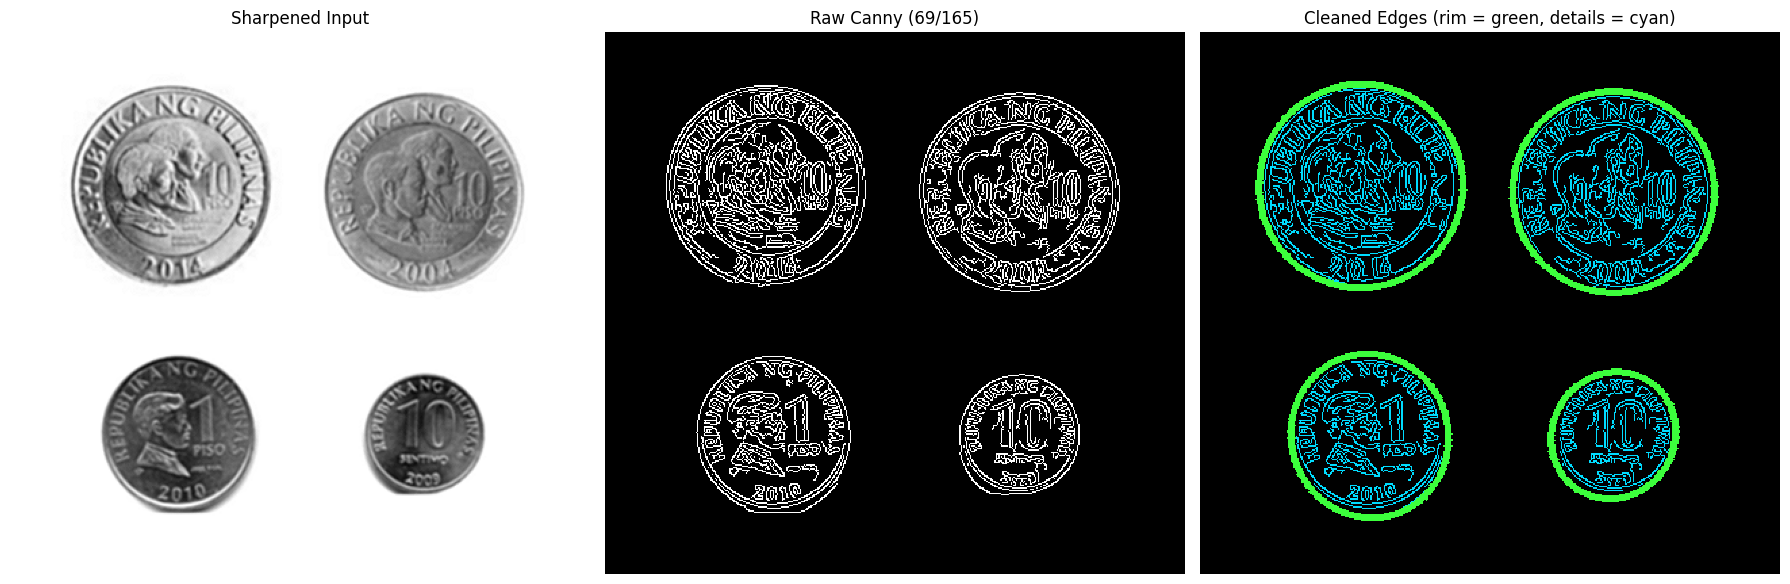

In [7]:
# --- 1. Rim edges: a crisp, continuous outline from the silhouette -----------------------
rim_edges = np.zeros_like(edges)
for coin in coins:
    cv2.ellipse(rim_edges, coin["ellipse"], 255, 2, cv2.LINE_AA)

# --- 2. Detail edges: keep Canny edges ONLY inside the coins ------------------------------
# Erode the mask a little so the rim isn't counted twice, and so background noise is dropped.
k_in = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
inside = cv2.erode(coin_mask, k_in)
detail_edges = cv2.bitwise_and(edges, inside)

# Drop isolated specks: keep only connected edge pieces that are long enough to matter
n, labels, stats, _ = cv2.connectedComponentsWithStats(detail_edges, connectivity=8)
min_len = 12  # pixels; raise to remove more clutter, lower to keep finer detail
keep = np.zeros_like(detail_edges)
for i in range(1, n):
    if stats[i, cv2.CC_STAT_AREA] >= min_len:
        keep[labels == i] = 255
detail_edges = keep

cleaned_edges = cv2.bitwise_or(rim_edges, detail_edges)

# --- 3. Colour-coded result: rim = green, inner details = cyan ---------------------------
edge_vis = np.zeros((*cleaned_edges.shape, 3), np.uint8)
edge_vis[detail_edges > 0] = (0, 220, 255)    # cyan (RGB): thin 1px detail lines
edge_vis[rim_edges > 0]    = (60, 255, 60)    # green (RGB): rim drawn on top

# --- Visualization -------------------------------------------------------------------------
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_sharpened, cmap='gray')
plt.title('Sharpened Input')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(edges, cmap='gray', interpolation='nearest')
plt.title(f'Raw Canny ({low_t}/{high_t})')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(edge_vis, interpolation='nearest')
plt.title('Cleaned Edges (rim = green, details = cyan)')
plt.axis('off')

plt.tight_layout()
plt.show()

# <h3>**Final Result: Detected Coins**

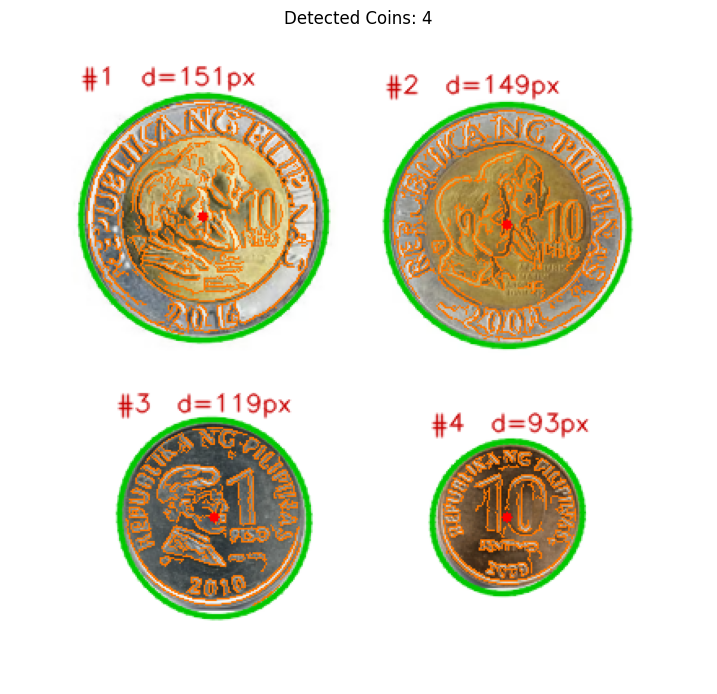

Coin  Centre (x, y)     Diameter (px)   Roundness 
#1    ( 118.6,  113.9)   150.6           0.998
#2    ( 305.4,  118.5)   148.9           0.998
#3    ( 125.1,  298.5)   118.9           0.993
#4    ( 305.3,  298.1)   93.0            0.991


In [8]:
# Draw the detected rims and detail edges directly on the original photo
overlay = img_display.copy()
overlay[detail_edges > 0] = (255, 120, 0)                       # detail edges (orange)

for i, coin in enumerate(coins, 1):
    cv2.ellipse(overlay, coin["ellipse"], (0, 200, 0), 2, cv2.LINE_AA)   # rim (green)
    (cx, cy), (d1, d2), _ = coin["ellipse"]
    diameter = (d1 + d2) / 2
    cv2.circle(overlay, (int(cx), int(cy)), 3, (255, 0, 0), -1)          # centre
    cv2.putText(overlay, f"#{i}  d={diameter:.0f}px", (int(cx - diameter / 2), int(cy - diameter / 2 - 6)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (200, 0, 0), 1, cv2.LINE_AA)

plt.figure(figsize=(9, 9))
plt.imshow(overlay)
plt.title(f'Detected Coins: {len(coins)}')
plt.axis('off')
plt.show()

# Measurement summary (diameter in pixels is handy for telling denominations apart)
print(f"{'Coin':<6}{'Centre (x, y)':<18}{'Diameter (px)':<16}{'Roundness':<10}")
for i, coin in enumerate(coins, 1):
    (cx, cy), (d1, d2), _ = coin["ellipse"]
    print(f"#{i:<5}({cx:6.1f}, {cy:6.1f})   {(d1 + d2) / 2:<16.1f}{coin['circularity']:.3f}")

# <h3>**Short Explanations**

○ Kernel used

    The sharpening step uses a 3x3 kernel:
    [[ 0, -1,  0]
     [-1,  5, -1]
     [ 0, -1,  0]]
    The center value 5 boosts the current pixel while the -1 neighbors subtract the surrounding brightness, which increases local contrast and emphasizes edges. A 7x7 elliptical structuring element is used for morphological closing/opening of the silhouette mask, and for eroding the interior region.

○ Convolution process

    The image is converted to grayscale and smoothed with median and Gaussian filters. The sharpening kernel is then applied with 'cv2.filter2D' to the Gaussian-blurred image, producing a version where edges and fine details have higher contrast.

○ Edge detection method

    'cv2.Canny' is used on the sharpened image. Instead of fixed thresholds (30, 150), the thresholds are computed automatically from the median brightness of the coin pixels only (0.5x and 1.2x), so the method adapts to different photos and is not skewed by the white background.

○ How the result was improved

    1. Silhouette mask: each pixel's colour distance from the white background is thresholded, closed, opened, and turned into a convex hull per coin. Colour distance keeps the bright silver rims that grayscale thresholding was cutting into.
    2. Shape filtering: blobs that are too small or not round enough are discarded, and an ellipse is fitted to each coin, which also handles the tilted coin.
    3. Rim edges: instead of relying on Canny to trace the outer boundary, the fitted ellipse gives a clean, continuous rim for every coin.
    4. Detail edges: Canny edges are kept only inside the coins (no closing step, which would merge thin lines into blobs), and small disconnected specks are removed with connected-component filtering, so the portraits, numerals and dates stay visible as thin lines.
    5. Visualization: rim and detail edges are color-coded and overlaid on the original photo, with each coin's center, diameter and roundness reported.